This notebook sources and curates the format of the Allen Brain Atlas CCF annotations in preparation for downstream analysis.

Operation(s):

1. Acquisition of annotation matrices and structure tree.
2. Flattening of structure tree and additional of subregions field
3. Definition of hypothalamic bounding box from annotation matrix
4. Initialization of Voxel Grid Zarr output file with annotation label matrix and regional mask grids

Output(s):
- DATADIR/7_spatial/abc/structure_tree.json
- DATADIR/7_spatial/abc/25um_annotation_mtx.nrrd
- DATADIR/7_spatial/structure_tree_processed.json
- DATADIR/7_spatial/sp_voxel.zarr (partial creation)
- DATADIR/7_spatial/bounding_box_ccf_mm.json
- DATADIR/7_spatial/bounding_box_voxels_25um.json

In [1]:
import warnings
import requests
import json

from pathlib import Path

import nrrd
import zarr
import numpy as np

from dotenv import dotenv_values
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle

from hm3d_utils.spatial import BoundingBox3D

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Settuping up filepaths from config
CONFIG = dotenv_values("../../config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "7_spatial" 
(OUTDIR / "abc").mkdir(exist_ok=True, parents=True) # DATADIR/7_spatial/abc

In [3]:
# Notebook specific configurations
N_VOXELS_BBOX_PADDING = 4 # number of voxels to expand bounding box border by (4 voxels = 100um)
CHUNK = [3, 144, 107] # chunk by 3 coronal slice
REGION_MIN_VOXELS = 500 # a region must have at least 500 voxels in bounding box to be considered

### Allen Brain Atlas Structure Tree

Regional annotations are hierarchical in nature. This hierarchy is provided as a nested dictionary of regions. This structure is instead flattened and saved.

In [4]:
# File source url from which to download file
structure_tree_url = "http://api.brain-map.org/api/v2/structure_graph_download/1.json"

# Output path on disk DATADIR/7_spatial/abc/structure_tree.json
structure_tree_outfile = OUTDIR / 'abc' / 'structure_tree.json'

# Download JSON file
response = requests.get(structure_tree_url)
with open(structure_tree_outfile, "wb") as f:
    f.write(response.content)

In [5]:
def build_node_info(tree, id_key="id", fields=("color_hex_triplet", "path", "acronym", "name")):
    result = {}
    stack = [(tree, [])]  # (node, parent_path)

    while stack:
        node, parent_path = stack.pop()
        
        node_id = node.get(id_key)
        current_path = parent_path + [node_id] if node_id else node_id
        
        if node_id is not None:
            result[node_id] = {}
            for field in fields:
                if field == "path":
                    # Always recompute path
                    result[node_id]["path"] = current_path
                else:
                    result[node_id][field] = node.get(field)
        
        # push children
        for child in node.get("children", []):
            stack.append((child, current_path))
    
    return result

In [6]:
# Load the raw file for processing
with open(structure_tree_outfile, 'r') as fp:
    structure_tree = json.load(fp)

# Step 1: remove redundant header information
structure_tree = structure_tree['msg'][0]

# Step 2: flatten the structure tree
structure_tree_processed = build_node_info(structure_tree)

# Step 3: quick fix to add # to hex color codes
for key, value in structure_tree_processed.items():
    structure_tree_processed[key]['color_hex_triplet'] = f"#{value['color_hex_triplet']}"

# Step 4: add a new field for 'subregions'
for node_id, node in structure_tree_processed.items():
    node.setdefault("subregions", [])

    for parent_id in node["path"]:
        parent = structure_tree_processed[parent_id]
        if node_id not in parent['subregions']:
            parent.setdefault("subregions", []).append(node_id)

In [7]:
# Save out the processed file to DATADIR/7_spatial/structure_tree_processed.json
outfile = OUTDIR/ 'structure_tree_processed.json'
with open(outfile, 'w') as fp:
    json.dump(structure_tree_processed, fp, indent=2)

### 25um Annotation Matrix

Voxel-wise regional annotations are provided at several resolution. 25um was the chosen resolution balancing data size and granularity. This dataset is provided as an .nrrd file. We will load this and subset to only the region of interest i.e. a bounding box surrounding.

In [8]:
# First we must download the 25um annotation matrix
# This file is downloaded to DATADIR/7_spatial/abc/25um_annotation_mtx.nrrd

annotation_nrrd_url = 'https://download.alleninstitute.org/informatics-archive/current-release/mouse_ccf/annotation/ccf_2017/annotation_25.nrrd'
annotation_nrrd_outfile = OUTDIR / 'abc' / '25um_annotation_mtx.nrrd'

response = requests.get(annotation_nrrd_url)
with open(annotation_nrrd_outfile, "wb") as f:
    f.write(response.content)

In [9]:
# We load the annotation matrix using pynrrd
annotation_25um, metadata_25um = nrrd.read(annotation_nrrd_outfile)
annotation_25um.shape

(528, 320, 456)

#### Constructing the bounding box

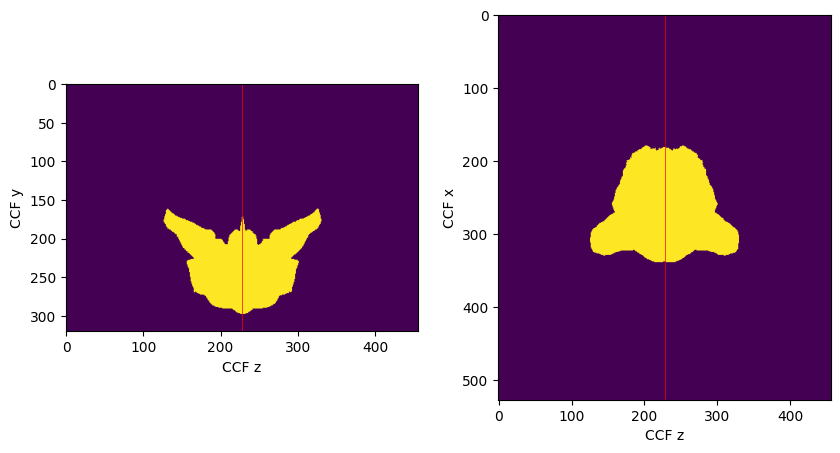

In [10]:
# We must now define the bounding box. The region of interest is defined by the hypothalamus + padding.

# Step 1: Identy z midline
z_midline = int(annotation_25um.shape[2] / 2)

# Step 2: get ids of all subregions of hypothalamus (includes self)
hy_region_ids = next((v['subregions'].copy() for k, v in structure_tree_processed.items() if v['acronym'] == 'HY'), None)

# quick fix to remove SFO (see dev-notes.md)
hy_region_ids.remove(338)

# Step 3: compute mask of hypothalamus
hy_mask = np.isin(annotation_25um, hy_region_ids)

# Let's visualize the midline for visual confirmation
coronal_collapsed = np.any(hy_mask, axis=0)
tranverse_collapsed = np.any(hy_mask, axis=1)
sagittal_collapsed = np.any(hy_mask, axis=2) # used later

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(coronal_collapsed)
axes[0].axvline(z_midline, color='r', lw=0.5)
axes[0].set_xlabel('CCF z')
axes[0].set_ylabel('CCF y')

axes[1].imshow(tranverse_collapsed)
axes[1].axvline(z_midline, color='r', lw=0.5)
axes[1].set_xlabel('CCF z')
axes[1].set_ylabel('CCF x')

plt.show();

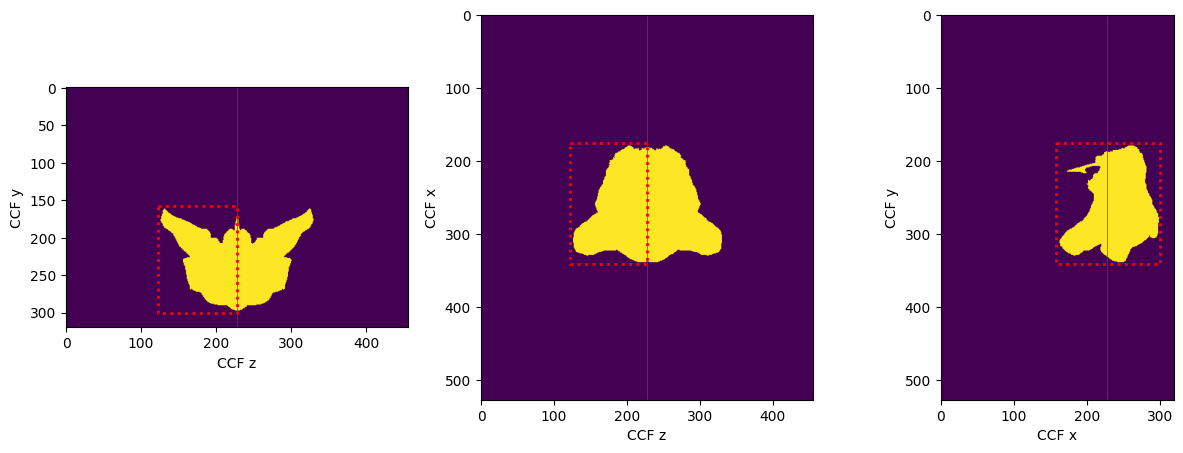

In [11]:
# Get coordinates of all hypothalamic voxels
coords = np.where(hy_mask)

# Bounding box is the minimum and maximum coordinate in each dimension independantly
bbox = {
    'min': np.array([int(coords[0].min()), int(coords[1].min()), int(coords[2].min())]),
    'max': np.array([int(coords[0].max()), int(coords[1].max()), int(coords[2].max())])
}
bbox
# We add padding to maximum values and subtract from minimum
bbox['min'] = bbox['min'] - N_VOXELS_BBOX_PADDING
bbox['max'] = bbox['max'] + N_VOXELS_BBOX_PADDING

# As a final step we set z max to z midline (see README.md)
bbox['max'][2] = z_midline

# Let's visualize this bounding box
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# -------------------------
# CORONAL (z vs y)
# -------------------------
axes[0].imshow(coronal_collapsed)
axes[0].axvline(z_midline, color='r', lw=0.5)
axes[0].set_xlabel('CCF z')
axes[0].set_ylabel('CCF y')

coronal_rect = Rectangle(
    (bbox['min'][2], bbox['min'][1]),
    bbox['max'][2] - bbox['min'][2],
    bbox['max'][1] - bbox['min'][1],
    edgecolor='r', facecolor='none', linewidth=2, linestyle=':'
)
axes[0].add_patch(coronal_rect)


# -------------------------
# TRANSVERSE (z vs x)
# -------------------------
axes[1].imshow(tranverse_collapsed)
axes[1].axvline(z_midline, color='r', lw=0.5)
axes[1].set_xlabel('CCF z')
axes[1].set_ylabel('CCF x')

transverse_rect = Rectangle(
    (bbox['min'][2], bbox['min'][0]),
    bbox['max'][2] - bbox['min'][2],
    bbox['max'][0] - bbox['min'][0],
    edgecolor='r', facecolor='none', linewidth=2, linestyle=':'
)
axes[1].add_patch(transverse_rect)


# -------------------------
# SAGITTAL (x vs y)
# -------------------------
axes[2].imshow(sagittal_collapsed)
axes[2].axvline(z_midline, color='r', lw=0.5)
axes[2].set_xlabel('CCF x')
axes[2].set_ylabel('CCF y')

sagittal_rect = Rectangle(
    (bbox['min'][1], bbox['min'][0]),
    bbox['max'][1] - bbox['min'][1],
    bbox['max'][0] - bbox['min'][0],
    edgecolor='r', facecolor='none', linewidth=2, linestyle=':'
)
axes[2].add_patch(sagittal_rect)

plt.show()

In [12]:
# We will create a BoundingBox3D object and save it to disk

voxel_bbox3d = BoundingBox3D(
    min_coord=bbox['min'],
    max_coord=bbox['max'],
    unit='25um Voxels'
)

outfile = OUTDIR / 'bounding_box_voxels_25um.json'
voxel_bbox3d.save(outfile)

# We will also a save a mm CCF coordinate version
mm_bbox3d = BoundingBox3D(
    min_coord=bbox['min'] * 25 / 1000,
    max_coord=bbox['max'] * 25 / 1000,
    unit='CCFv3 mm'
)

outfile = OUTDIR / 'bounding_box_ccf_mm.json'
mm_bbox3d.save(outfile)

#### Bounding the annotation matrix

In [13]:
# We now take the defined bounding box and subset the annotation matrix
annotation_25um_bounded = annotation_25um[
    int(voxel_bbox3d.min[0]) : int(voxel_bbox3d.max[0]) + 1, # +1 as inclusive of max voxel
    int(voxel_bbox3d.min[1]) : int(voxel_bbox3d.max[1]) + 1,
    int(voxel_bbox3d.min[2]) : int(voxel_bbox3d.max[2]) + 1  
]

annotation_25um_bounded.shape

(168, 144, 107)

In [14]:
# We will save this as the first voxel grid on disk at DATADIR/7_spatial/sp_voxels.zarr
store = zarr.open(OUTDIR / 'sp_voxels.zarr', mode='w')

store.create_array('region_labels', data=annotation_25um_bounded, overwrite=True, chunks=CHUNK)

<Array file:///REDACTED-path/HypoMap3D-data/v0.9/7_spatial/sp_voxels.zarr/region_labels shape=(168, 144, 107) dtype=uint32>

#### Precomputing region masks

In [15]:
# Identify region labels with sufficient observance (500 voxels default)
unique_regions, counts = np.unique(annotation_25um_bounded, return_counts=True)
unique_regions = unique_regions[counts > REGION_MIN_VOXELS].tolist()
if 0 in unique_regions:
    unique_regions.remove(0)  # drop empty region

# Pre-allocate masks dataset
masks_shape = (len(unique_regions),) + annotation_25um_bounded.shape
store.create_array('region_masks', shape=masks_shape, dtype=bool, overwrite=True, chunks=[1] + CHUNK)

<Array file:///REDACTED-path/HypoMap3D-data/v0.9/7_spatial/sp_voxels.zarr/region_masks shape=(176, 168, 144, 107) dtype=bool>

In [16]:
# Fill masks and collect acronyms
acronyms = []

for i, region_id in enumerate(unique_regions):
    region_dict = structure_tree_processed[region_id]

    acronyms.append(region_dict['acronym'])
    subunits = region_dict['subregions']

    mask = np.isin(annotation_25um_bounded, subunits)
    store['region_masks'][i, ...] = mask

# Add attributes
store['region_masks'].attrs['ids'] = unique_regions
store['region_masks'].attrs['acronyms'] = acronyms

In [17]:
store.tree()

/
├── region_labels (168, 144, 107) uint32
└── region_masks (176, 168, 144, 107) bool